# MODIS + VIIRS hotspot harmonization (Algeria, pilot)

Goal: one consistent monthly hotspot series from 2000 to today, so the sensor of origin no longer matters.

Pipeline: load and crop -> inspect -> raw comparison (the "before") -> clean and aggregate -> calibrate in the overlap -> harmonized series -> export for the app.

Status: skeleton. Column names follow the FIRMS archive format; check them against your real files in section 1.

## 0. Setup and parameters

All choices that affect results live here, so you can change them in one place and rerun. Each one should be justified in your write-up.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAW = Path("../data/raw")
OUT = Path("../data/processed")
OUT.mkdir(parents=True, exist_ok=True)

# Pilot area: northern Algeria (wildfires), avoids most Saharan gas flares
LAT_MIN, LAT_MAX = 34.0, 37.2
LON_MIN, LON_MAX = -2.3, 8.7

# Confidence rules (check the value formats in section 1)
MODIS_MIN_CONF = 30           # MODIS confidence is numeric 0-100
VIIRS_KEEP_CONF = {"n", "h"}  # VIIRS confidence is l / n / h

# Spatial units
DEDUP_CELL = 0.01   # ~1 km, used to count "occupied cells per day"
GRID = 0.25         # grid of the final monthly product, in degrees

OVERLAP_START = "2013-01-01"  # first full month with VIIRS
LAST_FULL_MONTH = "2026-10-01"  # exclude the current, incomplete month

## 1. Load and crop

Question answered: what is in the files, and can I fit them in memory?
Load only the columns we need and crop to the pilot area immediately, since everything after this is smaller and faster.

In [17]:
USECOLS = ["latitude", "longitude", "acq_date", "acq_time", "satellite",
           "confidence", "frp", "daynight", "scan", "track"]

def load_sensor(pattern):
    # FIRMS delivers two files per sensor: *archive* (standard processing, historical)
    # and *nrt* (near real time, the most recent months). We load both.
    parts = []
    for f in sorted(RAW.glob(pattern)):          # "archive" sorts before "nrt"
        df = pd.read_csv(f, usecols=lambda c: c in USECOLS + ["type"],
                         dtype={"satellite": "category", "daynight": "category"})
        df = df[df.latitude.between(LAT_MIN, LAT_MAX) & df.longitude.between(LON_MIN, LON_MAX)]
        df["acq_date"] = pd.to_datetime(df["acq_date"])
        print(f"{f.name:32s} {len(df):>9,d} rows | {df.acq_date.min().date()} -> {df.acq_date.max().date()}")
        parts.append(df)
    out = pd.concat(parts, ignore_index=True)
    # If the two files overlap in time, the same detection would appear twice.
    # Keep the first copy, which is the archive (standard processing) version.
    before = len(out)
    out = out.drop_duplicates(subset=["latitude", "longitude", "acq_date", "acq_time", "satellite"], keep="first")
    print(f"  duplicates removed across files: {before - len(out):,d}")
    return out

modis = load_sensor("modis*.csv")
viirs = load_sensor("viirs*.csv")
modis.to_parquet(OUT / "modis_north.parquet", index=False)
viirs.to_parquet(OUT / "viirs_north.parquet", index=False)


modis_archive.csv                   93,215 rows | 2000-11-02 -> 2026-08-31
modis_nrt.csv                          284 rows | 2026-09-01 -> 2026-11-06
  duplicates removed across files: 0
viirs_archive.csv                  304,565 rows | 2012-07-04 -> 2026-07-31
viirs_nrt.csv                        9,540 rows | 2026-08-01 -> 2026-11-02
  duplicates removed across files: 0


In [18]:
# Reload from parquet on later runs (much faster than CSV)
# modis = pd.read_parquet(OUT / "modis_north.parquet")
# viirs = pd.read_parquet(OUT / "viirs_north.parquet")

for name, d in [("MODIS", modis), ("VIIRS", viirs)]:
    print(name, "| rows:", f"{len(d):,d}", "| dates:", d.acq_date.min().date(), "->", d.acq_date.max().date())
    print("  confidence values:", d["confidence"].astype(str).unique()[:8])
    print("  satellites:", d["satellite"].unique().tolist())
    if "type" in d.columns:
        print("  type values:", d["type"].unique().tolist(), "(check FIRMS docs for meaning)")

MODIS | rows: 93,499 | dates: 2000-11-02 -> 2026-11-06
  confidence values: <ArrowStringArray>
['51', '61', '65', '0', '96', '100', '41', '48']
Length: 8, dtype: str
  satellites: ['Terra', 'Aqua']
  type values: [2.0, 0.0, 3.0, nan] (check FIRMS docs for meaning)
VIIRS | rows: 314,105 | dates: 2012-07-04 -> 2026-11-02
  confidence values: <ArrowStringArray>
['n', 'l', 'h']
Length: 3, dtype: str
  satellites: ['SNPP']
  type values: [2.0, 0.0, 3.0, nan] (check FIRMS docs for meaning)


## 2. Raw comparison (the "before" picture)

Question answered: how different do the two sensors look before any correction?
This becomes the first figure of your demo and your write-up.

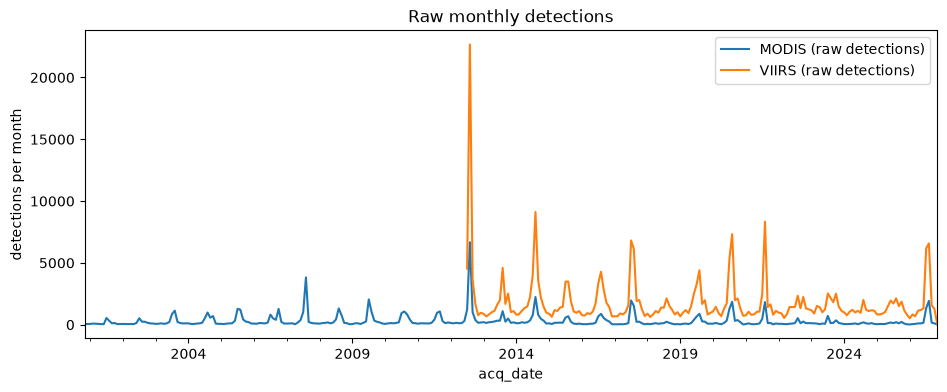

In [19]:
def monthly_raw(d):
    return d.groupby(d.acq_date.dt.to_period("M")).size()

raw_m, raw_v = monthly_raw(modis), monthly_raw(viirs)
ax = raw_m.plot(label="MODIS (raw detections)", figsize=(11, 4))
raw_v.plot(ax=ax, label="VIIRS (raw detections)")
ax.set_ylabel("detections per month"); ax.legend(); ax.set_title("Raw monthly detections")
plt.show()

## 3. Clean and aggregate

Three steps, each with a reason:
1. **Confidence filter**, so low-quality detections do not inflate counts.
2. **Occupied-cell counting**: VIIRS pixels are smaller, so raw counts are not comparable. Counting unique ~1 km cells with a detection per day reduces the resolution gap.
3. **Deduplication across satellites**: the same fire seen by two satellites on the same day counts once.

In [20]:
def clean(d, sensor):
    d = d.copy()
    conf = d["confidence"].astype(str).str.lower()
    if sensor == "modis":
        d = d[pd.to_numeric(conf, errors="coerce") >= MODIS_MIN_CONF]
    else:
        d = d[conf.isin(VIIRS_KEEP_CONF)]

    # Source-type filter: keep vegetation fires only
    d = add_cell(d)
    has_type = d["type"].notna()
    in_static = pd.MultiIndex.from_frame(d[["clat", "clon"]]).isin(static_idx)
    keep = (has_type & (d["type"] == 0)) | (~has_type & ~in_static)
    return d[keep]

def occupied_cells(d):
    d = d.copy()
    d["clat"] = (d.latitude / DEDUP_CELL).round().astype(int)
    d["clon"] = (d.longitude / DEDUP_CELL).round().astype(int)
    # one row per (cell, day), regardless of how many satellites saw it
    return d.drop_duplicates(subset=["clat", "clon", "acq_date"])

def to_monthly_grid(d):
    d = d.copy()
    d["lat"] = (np.floor(d.latitude / GRID) * GRID + GRID / 2).round(3)
    d["lon"] = (np.floor(d.longitude / GRID) * GRID + GRID / 2).round(3)
    d["year"], d["month"] = d.acq_date.dt.year, d.acq_date.dt.month
    return d.groupby(["lat", "lon", "year", "month"], as_index=False).size().rename(columns={"size": "count"})

m_clean = occupied_cells(clean(modis, "modis"))
v_clean = occupied_cells(clean(viirs, "viirs"))
print("MODIS:", len(modis), "->", len(m_clean), "| VIIRS:", len(viirs), "->", len(v_clean))

grid_m, grid_v = to_monthly_grid(m_clean), to_monthly_grid(v_clean)

MODIS: 93499 -> 57637 | VIIRS: 314105 -> 75195


## 4. Calibrate in the overlap

Question answered: how do monthly VIIRS counts relate to monthly MODIS counts when both see the same fires?
Start with the simplest model, a single ratio. Validate by leaving out whole years, because neighbouring months and fires are correlated and a random split would flatter the result.

165 overlap months


C:\Users\MICROSOFT PRO DZ\AppData\Local\Temp\ipykernel_7216\1612383537.py:7: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  both = pd.concat([sm.rename("modis"), sv.rename("viirs")], axis=1).dropna()


<Axes: title={'center': 'Monthly counts, overlap period'}, xlabel='modis', ylabel='viirs'>

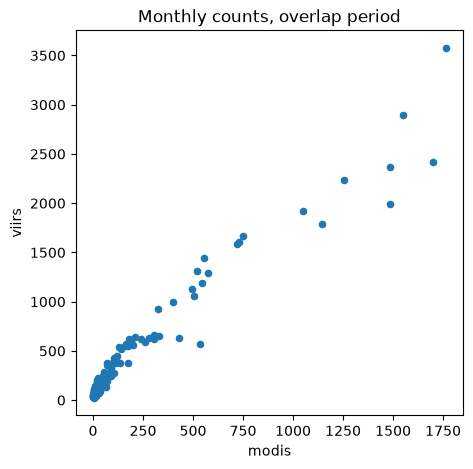

In [21]:
def region_monthly(g):
    s = g.groupby(["year", "month"])["count"].sum()
    s.index = pd.to_datetime(dict(year=s.index.get_level_values(0), month=s.index.get_level_values(1), day=1))
    return s

sm, sv = region_monthly(grid_m), region_monthly(grid_v)
both = pd.concat([sm.rename("modis"), sv.rename("viirs")], axis=1).dropna()
both = both[(both.index >= OVERLAP_START) & (both.index <= LAST_FULL_MONTH)]
print(len(both), "overlap months")
both.plot.scatter(x="modis", y="viirs", figsize=(5, 5), title="Monthly counts, overlap period")

In [22]:
b, a = np.polyfit(both.modis, both.viirs, 1)       # slope, intercept
print(f"VIIRS ≈ {a:.0f} + {b:.2f} × MODIS")
print("ratio-only model uses:", round(both.viirs.sum() / both.modis.sum(), 2))

VIIRS ≈ 115 + 1.69 × MODIS
ratio-only model uses: 2.43


In [23]:
# 1. Which cells are active in nearly every month?
v = v_clean[v_clean.acq_date >= OVERLAP_START].copy()
v["ym"] = v.acq_date.dt.to_period("M")
months_active = v.groupby(["clat", "clon"])["ym"].nunique()
persistent = months_active[months_active >= 0.9 * v["ym"].nunique()]
share = pd.MultiIndex.from_frame(v[["clat", "clon"]]).isin(persistent.index).mean()
print(len(persistent), "cells active in >=90% of months")
print(f"share of VIIRS cell-days from those cells: {share:.1%}")

# 2. Does the file label them itself?
if "type" in v_clean.columns:
    print(v_clean["type"].value_counts())

0 cells active in >=90% of months
share of VIIRS cell-days from those cells: 0.0%
type
0.0    72791
Name: count, dtype: int64


In [24]:
print("MODIS columns:", modis.columns.tolist())      # does MODIS have 'type' too?

no_type = v_clean[v_clean["type"].isna()]
print(len(no_type), "VIIRS rows without type")
print(no_type.acq_date.min().date(), "->", no_type.acq_date.max().date())

MODIS columns: ['latitude', 'longitude', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'confidence', 'frp', 'daynight', 'type']
2404 VIIRS rows without type
2026-08-01 -> 2026-11-02


In [25]:
print("MODIS rows without type:", modis["type"].isna().sum())
print("MODIS type values:\n", modis["type"].value_counts(dropna=False))

def add_cell(d):
    d = d.copy()
    d["clat"] = (d.latitude / DEDUP_CELL).round().astype(int)
    d["clon"] = (d.longitude / DEDUP_CELL).round().astype(int)
    return d

# Learn from the labelled VIIRS rows (most detections, most sensitive sensor)
lab = add_cell(viirs[viirs["type"].notna()])
nonveg_share = (lab["type"] != 0).groupby([lab["clat"], lab["clon"]]).mean()
static_idx = nonveg_share[nonveg_share >= 0.5].index      # a MultiIndex of (clat, clon)
print(len(static_idx), "cells flagged as non-vegetation sources")

MODIS rows without type: 284
MODIS type values:
 type
0.0    65379
2.0    27661
NaN      284
3.0      175
Name: count, dtype: int64
209 cells flagged as non-vegetation sources


In [26]:
# Leave-one-year-out validation of the ratio model: viirs ~ ratio * modis
years = sorted(set(both.index.year))
errors = []
for y in years:
    train, test = both[both.index.year != y], both[both.index.year == y]
    ratio = train.viirs.sum() / train.modis.sum()
    pred = ratio * test.modis
    errors.append(pd.DataFrame({"year": y, "obs": test.viirs, "pred": pred}))
cv = pd.concat(errors)
rmse = np.sqrt(((cv.obs - cv.pred) ** 2).mean())
mape = ((cv.obs - cv.pred).abs() / cv.obs.replace(0, np.nan)).median()
print(f"leave-one-year-out RMSE: {rmse:,.0f} | median relative error: {mape:.1%}")

RATIO = both.viirs.sum() / both.modis.sum()   # final ratio, fitted on all overlap months
print("final ratio VIIRS/MODIS:", round(RATIO, 3))

leave-one-year-out RMSE: 290 | median relative error: 52.2%
final ratio VIIRS/MODIS: 2.428


In [27]:
def loyo(both, fit, predict):
    out = []
    for y in sorted(set(both.index.year)):
        train, test = both[both.index.year != y], both[both.index.year == y]
        params = fit(train)                       # fit WITHOUT year y
        pred = predict(params, test.modis)        # predict year y
        out.append(pd.DataFrame({"obs": test.viirs, "pred": pred}))
    cv = pd.concat(out)
    rel = (cv.obs - cv.pred).abs() / cv.obs
    rmse = np.sqrt(((cv.obs - cv.pred) ** 2).mean())
    return rmse, rel.median(), cv

models = {
    "ratio":   (lambda t: t.viirs.sum() / t.modis.sum(),
                lambda p, m: p * m),
    "linear":  (lambda t: np.polyfit(t.modis, t.viirs, 1),
                lambda p, m: p[0] * m + p[1]),
    "log-log": (lambda t: np.polyfit(np.log(t.modis + 1), np.log(t.viirs + 1), 1),
                lambda p, m: np.exp(p[1] + p[0] * np.log(m + 1)) - 1),
}

for name, (fit, pred) in models.items():
    rmse, mre, _ = loyo(both, fit, pred)
    print(f"{name:8s} RMSE {rmse:7.0f} | median relative error {mre:.1%}")

ratio    RMSE     290 | median relative error 52.2%
linear   RMSE     142 | median relative error 28.8%
log-log  RMSE     159 | median relative error 16.5%


In [30]:
for name in ["linear", "log-log"]:
    fit, pred = models[name]
    _, _, cv = loyo(both, fit, pred)
    cv = cv.join(both["modis"])                           # add the MODIS count to each held-out month
    cv["level"] = pd.qcut(cv["modis"], 3, labels=["quiet", "medium", "busy"])
    cv["rel_err"] = (cv.obs - cv.pred).abs() / cv.obs     # size of the mistake, as a share of the truth
    cv["signed"] = (cv.pred - cv.obs) / cv.obs            # direction: + means over-predicted
    print(name)
    print(cv.groupby("level", observed=True).agg(
        median_rel_err=("rel_err", "median"),
        bias=("signed", "mean"),
        n=("obs", "size")).round(3))

linear
        median_rel_err   bias   n
level                            
quiet            0.711  0.944  56
medium           0.247  0.232  54
busy             0.199 -0.117  55
log-log
        median_rel_err   bias   n
level                            
quiet            0.180 -0.003  56
medium           0.201  0.182  54
busy             0.137 -0.032  55


## 5. Harmonized series and export

Before the overlap we use MODIS scaled to the VIIRS level; from the overlap start we use VIIRS directly.
The export has the exact columns the app expects: `lat, lon, year, month, count` (plus `source` for transparency).

In [28]:
cut = pd.Timestamp(OVERLAP_START)
def with_date(g): return g.assign(date=pd.to_datetime(dict(year=g.year, month=g.month, day=1)))

gm, gv = with_date(grid_m), with_date(grid_v)
gm = gm[(gm.date < cut)].copy();  gm["count"] = (gm["count"] * RATIO).round().astype(int); gm["source"] = "MODIS (scaled)"
gv = gv[(gv.date >= cut) & (gv.date <= LAST_FULL_MONTH)].copy();                gv["source"] = "VIIRS"

harmonized = pd.concat([gm, gv], ignore_index=True)[["lat", "lon", "year", "month", "count", "source"]]
harmonized.to_parquet(OUT / "monthly_grid.parquet", index=False)
print(len(harmonized), "rows written to", OUT / "monthly_grid.parquet")

17212 rows written to ..\data\processed\monthly_grid.parquet


## 6. Sanity checks (the "after" picture)

Question answered: is the harmonized series continuous, and do the peaks fall in the fire season?
Look for a visible jump at the 2013 switch; a jump means the calibration is off.

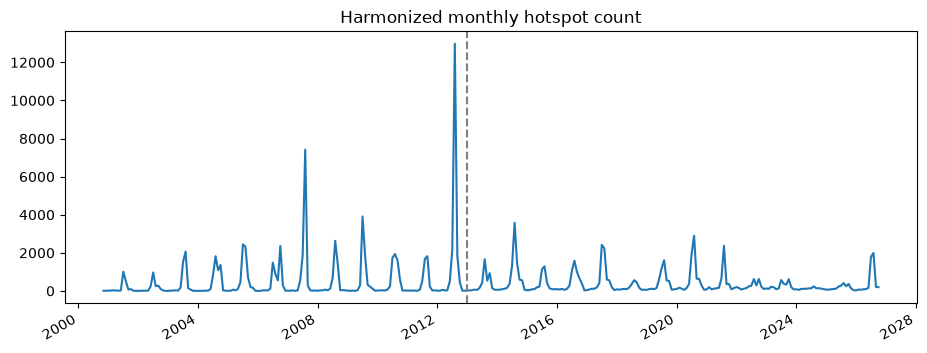

month
8     57850
7     32694
9     17367
10    12261
Name: count, dtype: int64


In [29]:
series = harmonized.groupby(["year", "month"])["count"].sum()
series.index = pd.to_datetime(dict(year=series.index.get_level_values(0), month=series.index.get_level_values(1), day=1))
series.plot(figsize=(11, 4), title="Harmonized monthly hotspot count")
plt.axvline(cut, color="grey", linestyle="--"); plt.show()

# Seasonal check: which months peak?
print(harmonized.groupby("month")["count"].sum().sort_values(ascending=False).head(4))

## Next steps
- Point `app/app.py` at `data/processed/monthly_grid.parquet`.
- Try per-month or per-region ratios if the single ratio leaves a clear seasonal error.
- Add confidence intervals from the leave-one-year-out errors to the app.
- Document every parameter from section 0 in the README.

In [31]:
# --- candidate models (each: fit on training years, predict a held-out year) ---
def fit_loglog_smear(t):
    x, y = np.log(t.modis + 1), np.log(t.viirs + 1)
    b, a = np.polyfit(x, y, 1)                    # line in log space
    smear = np.mean(np.exp(y - (a + b * x)))      # correction for the back-transform
    return b, a, smear

def pred_loglog_smear(p, m):
    b, a, smear = p
    return smear * np.exp(a + b * np.log(m + 1)) - 1

models["log-log+smear"] = (fit_loglog_smear, pred_loglog_smear)

# --- compare: overall error, then error and bias by activity level ---
for name in ["linear", "log-log", "log-log+smear"]:
    fit, pred = models[name]
    rmse, mre, cv = loyo(both, fit, pred)
    cv = cv.join(both["modis"])
    cv["level"] = pd.qcut(cv["modis"], 3, labels=["quiet", "medium", "busy"])
    cv["rel_err"] = (cv.obs - cv.pred).abs() / cv.obs

    print(f"\\n{name}: RMSE {rmse:.0f} | median relative error {mre:.1%}")
    rows = []
    for lvl, g in cv.groupby("level", observed=True):
        rows.append(dict(level=lvl, n=len(g),
                         median_rel_err=g.rel_err.median(),
                         total_bias=g.pred.sum() / g.obs.sum() - 1))   # + means over-predicts
    print(pd.DataFrame(rows).round(3).to_string(index=False))

\nlinear: RMSE 142 | median relative error 28.8%
 level  n  median_rel_err  total_bias
 quiet 56           0.711       0.664
medium 54           0.247       0.112
  busy 55           0.199      -0.075
\nlog-log: RMSE 159 | median relative error 16.5%
 level  n  median_rel_err  total_bias
 quiet 56           0.180      -0.087
medium 54           0.201       0.099
  busy 55           0.137      -0.105
\nlog-log+smear: RMSE 146 | median relative error 16.7%
 level  n  median_rel_err  total_bias
 quiet 56           0.190      -0.048
medium 54           0.231       0.144
  busy 55           0.113      -0.068


In [32]:
sat_year = modis.groupby([modis.acq_date.dt.year, "satellite"], observed=True).size().unstack(fill_value=0)
print(sat_year)

satellite  Aqua  Terra
acq_date              
2000          0    104
2001          0   1581
2002        642   1129
2003       1704   1483
2004       1916   1586
2005       2212   1995
2006       2217   1776
2007       3679   2597
2008       2056   1596
2009       2570   2114
2010       2374   1897
2011       1991   1687
2012       6070   4502
2013       2017   1828
2014       3363   2438
2015       1390   1122
2016       1949   1231
2017       2718   1712
2018        576    582
2019       1661   1326
2020       2679   2174
2021       1658   1442
2022        996    686
2023       1085   1017
2024        526    521
2025        643    642
2026       1968   2071


In [7]:
import shutil
from pathlib import Path

def load_region(region, bbox=None, chunk=500_000):
    """CSV -> compact parquet partitioned by year. Returns the static-source cells of this region.
    bbox = (west, south, east, north) or None to keep the whole file."""
    base = Path("../data/raw") / region
    store = Path("../data/processed") / region
    if store.exists():
        shutil.rmtree(store)                     # rerun from scratch, so no duplicates pile up
    stats = None                                 # per-cell counts for the static-source rule

    for sensor in ["modis", "viirs"]:
        out = store / sensor
        for f in sorted(base.glob(f"{sensor}*.csv")):
            reader = pd.read_csv(f, chunksize=chunk,
                                 usecols=lambda c: c in ["latitude","longitude","acq_date","frp",
                                                         "daynight","satellite","confidence","type"],
                                 dtype={"confidence": str, "satellite": str, "daynight": str})
            for ch in reader:
                if bbox:
                    w, s, e, n = bbox
                    ch = ch[ch.latitude.between(s, n) & ch.longitude.between(w, e)]
                if ch.empty:
                    continue

                conf = ch["confidence"].str.lower()
                if sensor == "modis":
                    ok = pd.to_numeric(conf, errors="coerce") >= MODIS_MIN_CONF
                else:
                    ok = conf.isin(VIIRS_KEEP_CONF)
                vtype = ch["type"] if "type" in ch.columns else pd.Series(np.nan, index=ch.index)

                d = pd.DataFrame({
                    "latitude": ch.latitude, "longitude": ch.longitude,
                    "acq_date": pd.to_datetime(ch.acq_date),
                    "frp": ch.frp.astype("float32"),
                    "is_day": (ch.daynight == "D").astype("int8"),
                    "satellite": ch.satellite,
                    "conf_ok": ok.to_numpy(),
                    "vtype": vtype.fillna(-1).astype("int8"),     # -1 means no label
                })
                d["year"] = d.acq_date.dt.year.astype("int16")

                if sensor == "viirs":                              # learn static cells from labelled VIIRS rows
                    lab = d[d.vtype >= 0]
                    if len(lab):
                        k = pd.DataFrame({"clat": (lab.latitude / DEDUP_CELL).round().astype(int),
                                          "clon": (lab.longitude / DEDUP_CELL).round().astype(int),
                                          "nonveg": (lab.vtype != 0).astype(int)})
                        g = k.groupby(["clat", "clon"])["nonveg"].agg(["sum", "count"])
                        stats = g if stats is None else stats.add(g, fill_value=0)

                d.to_parquet(out, partition_cols=["year"], index=False)   # appends a file per year per chunk
            print(f"  loaded {f.name}")

    share = stats["sum"] / stats["count"]
    static_idx = share[share >= 0.5].index
    print(region, "->", len(static_idx), "static-source cells")
    return static_idx

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Confidence rules
MODIS_MIN_CONF = 30            # MODIS confidence is numeric 0-100
VIIRS_KEEP_CONF = {"n", "h"}   # VIIRS confidence is l / n / h

# Spatial units
DEDUP_CELL = 0.01              # ~1 km cell used to count occupied cells per day
GRID = 0.25                    # final monthly grid, in degrees

# Dates
OVERLAP_START = "2013-01-01"
LAST_FULL_MONTH = "2026-10-01"

def to_monthly_grid(d):
    d = d.copy()
    d["lat"] = (np.floor(d.latitude / GRID) * GRID + GRID / 2).round(3)
    d["lon"] = (np.floor(d.longitude / GRID) * GRID + GRID / 2).round(3)
    d["year"], d["month"] = d.acq_date.dt.year, d.acq_date.dt.month
    return d.groupby(["lat", "lon", "year", "month"], as_index=False).size().rename(columns={"size": "count"})

In [8]:
def grid_from_store(region, sensor, static_idx):
    parts = []
    for ydir in sorted((Path("../data/processed") / region / sensor).glob("year=*")):
        d = pd.read_parquet(ydir)
        d = d[d.conf_ok].copy()
        d["clat"] = (d.latitude / DEDUP_CELL).round().astype(int)
        d["clon"] = (d.longitude / DEDUP_CELL).round().astype(int)

        has_type = d.vtype >= 0
        in_static = pd.MultiIndex.from_frame(d[["clat", "clon"]]).isin(static_idx)
        d = d[(has_type & (d.vtype == 0)) | (~has_type & ~in_static)]   # same rule as before
        d = d.drop_duplicates(subset=["clat", "clon", "acq_date"])      # occupied cells per day
        parts.append(to_monthly_grid(d))                                # your existing function
    return pd.concat(parts, ignore_index=True)

REGIONS = {"algeria": (-2.3, 34.0, 8.7, 37.2),   # (west, south, east, north), the pilot box
           "portugal": None,
           "zambia": None}

for region, bbox in REGIONS.items():
    static_idx = load_region(region, bbox)
    gm = grid_from_store(region, "modis", static_idx)
    gv = grid_from_store(region, "viirs", static_idx)
    gm.to_parquet(f"../data/processed/{region}_grid_m.parquet", index=False)
    gv.to_parquet(f"../data/processed/{region}_grid_v.parquet", index=False)
    print(region, "| MODIS cell-days:", int(gm["count"].sum()), "| VIIRS cell-days:", int(gv["count"].sum()))

  loaded modis_archive.csv
  loaded modis_nrt.csv
  loaded viirs_archive.csv
  loaded viirs_nrt.csv
algeria -> 209 static-source cells
algeria | MODIS cell-days: 57637 | VIIRS cell-days: 75195
  loaded modis_archive.csv
  loaded modis_nrt.csv
  loaded viirs_archive.csv
  loaded viirs_nrt.csv
portugal -> 39 static-source cells
portugal | MODIS cell-days: 65360 | VIIRS cell-days: 45762
  loaded modis_archive.csv
  loaded modis_nrt.csv
  loaded viirs_archive.csv
  loaded viirs_nrt.csv
zambia -> 802 static-source cells
zambia | MODIS cell-days: 4560004 | VIIRS cell-days: 6927367


In [9]:
def monthly_total(g):
    s = g.groupby(["year", "month"])["count"].sum()
    s.index = pd.to_datetime(dict(year=s.index.get_level_values(0),
                                  month=s.index.get_level_values(1), day=1))
    return s

def load_both(region):
    gm = pd.read_parquet(f"../data/processed/{region}_grid_m.parquet")
    gv = pd.read_parquet(f"../data/processed/{region}_grid_v.parquet")
    b = pd.concat([monthly_total(gm).rename("modis"), monthly_total(gv).rename("viirs")], axis=1)
    months = pd.date_range(OVERLAP_START, LAST_FULL_MONTH, freq="MS")
    return b.reindex(months).fillna(0)          # a month with no detections counts as 0

def fit_loglog_smear(t):
    x, y = np.log(t.modis + 1), np.log(t.viirs + 1)
    b, a = np.polyfit(x, y, 1)
    smear = np.mean(np.exp(y - (a + b * x)))
    return b, a, smear

def pred_loglog_smear(p, m):
    b, a, smear = p
    return smear * np.exp(a + b * np.log(m + 1)) - 1

data = {r: load_both(r) for r in ["algeria", "portugal", "zambia"]}
p_alg = fit_loglog_smear(data["algeria"])       # the model learned in Algeria only

rows = []
for r, t in data.items():
    p_own = fit_loglog_smear(t)
    obs = t.viirs
    for label, p in [("own fit", p_own), ("Algeria model", p_alg)]:
        pred = pred_loglog_smear(p, t.modis)
        rows.append(dict(region=r, model=label,
                         overlap_ratio=round(t.viirs.sum() / t.modis.sum(), 2),
                         slope_b=round(p[0], 2),
                         median_rel_err=round(((obs - pred).abs() / obs.replace(0, np.nan)).median(), 3),
                         total_bias=round(pred.sum() / obs.sum() - 1, 3)))
print(pd.DataFrame(rows).to_string(index=False))

C:\Users\MICROSOFT PRO DZ\AppData\Local\Temp\ipykernel_25592\4125203966.py:10: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  b = pd.concat([monthly_total(gm).rename("modis"), monthly_total(gv).rename("viirs")], axis=1)
C:\Users\MICROSOFT PRO DZ\AppData\Local\Temp\ipykernel_25592\4125203966.py:10: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  b = pd.concat([monthly_total(gm).rename("modis"), monthly_total(gv).rename("viirs")], axis=1)


  region         model  overlap_ratio  slope_b  median_rel_err  total_bias
 algeria       own fit           2.43     0.65           0.173      -0.042
 algeria Algeria model           2.43     0.65           0.173      -0.042
portugal       own fit           1.46     0.79           0.218      -0.020
portugal Algeria model           1.46     0.65           1.128       0.558
  zambia       own fit           2.59     0.89           0.143       0.028
  zambia Algeria model           2.59     0.65           0.724      -0.814
